<a href="https://colab.research.google.com/github/luzangelacarabali/modelos-difusion-ia-generativa/blob/main/tarea-generacion%20imagenes/punto%201/punto%201B/Punto1B_Difusion_CIFAR10_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Punto 1B · Modelo de difusión (DDPM) con imágenes a color: **CIFAR-10**

**Universidad Autónoma de Occidente** · Inteligencia Artificial Generativa · Ingeniería de Datos e IA
Profesores: Jesús Alfonso López – José Luis Paniagua

Ahora pasamos de imágenes en escala de grises (28×28×1) a imágenes **a color de 32×32×3**: CIFAR-10 (aviones, carros, pájaros, gatos, venados, perros, ranas, caballos, barcos y camiones). Es un salto grande de dificultad: hay tres canales, fondos, texturas y objetos en posiciones muy variadas.

### ¿Qué hubo que modificar respecto al código del ejemplo?

| Componente | Ejemplo (Fashion MNIST) | Esta versión (CIFAR-10) | Por qué |
|---|---|---|---|
| Datos | `fashion_mnist`, 28×28×1 | `cifar10`, 32×32×3 | enunciado |
| `prepare_batch` | añade eje de canal `[..., tf.newaxis]` | ya trae 3 canales + **volteo horizontal aleatorio** | aumento de datos barato y válido para fotos |
| Entrada/salida de la UNet | `ZeroPadding2D` 28→34 y recorte final a 28 | sin relleno ni recorte (32 ya es divisible por 8); **salida de 3 canales** | forma de la imagen |
| Capacidad | 16→32→64→128 filtros | 64→128→256→256 filtros + MLP para el tiempo | el color y las texturas exigen más capacidad |
| Pasos de difusión | T = 4000 | **T = 1000** (como el DDPM original) | 4× más rápido al generar, sin pérdida apreciable para 32×32 |
| Pesos para generar | los del último entrenamiento | **promedio móvil exponencial (EMA)** de los pesos | truco estándar en difusión: muestras mucho más limpias |
| Muestreo | DDPM (T pasos, Python puro) | DDPM compilado con `tf.function` + **DDIM** (100 pasos) | velocidad para poder evaluar con miles de imágenes |
| Métricas | — | **FID, KID e Inception Score con InceptionV3 (ImageNet)** | métricas estándar para imágenes naturales a color |

> ⚙️ **Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)**. El entrenamiento completo toma ~30–40 min en una T4.

## 0. Configuración del entorno

In [20]:
import sys, os
assert sys.version_info >= (3, 7)

IS_COLAB = "google.colab" in sys.modules
if IS_COLAB:
    os.environ["TF_USE_LEGACY_KERAS"] = "1"   # Keras 2 (tf_keras), igual que el notebook original
    import tf_keras

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from packaging import version
from scipy import linalg

assert version.parse(tf.__version__) >= version.parse("2.8.0")
print("TensorFlow:", tf.__version__)
if not tf.config.list_physical_devices("GPU"):
    print("⚠️ No se detectó GPU. Activa la GPU antes de entrenar.")
else:
    print("GPU detectada:", tf.config.list_physical_devices("GPU")[0])

TensorFlow: 2.21.0
GPU detectada: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


## 1. Carga de CIFAR-10

In [21]:
CLASS_NAMES = ["avión", "automóvil", "pájaro", "gato", "venado",
               "perro", "rana", "caballo", "barco", "camión"]

(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()
y_train_full, y_test = y_train_full.ravel(), y_test.ravel()
X_train_full = X_train_full.astype(np.float32) / 255
X_test = X_test.astype(np.float32) / 255
X_train, X_valid = X_train_full[:-5000], X_train_full[-5000:]
y_train, y_valid = y_train_full[:-5000], y_train_full[-5000:]
IMG_SHAPE = X_train.shape[1:]   # (32, 32, 3)

print("Entrenamiento:", X_train.shape, "| Validación:", X_valid.shape, "| Prueba:", X_test.shape)

Entrenamiento: (45000, 32, 32, 3) | Validación: (5000, 32, 32, 3) | Prueba: (10000, 32, 32, 3)


Imágenes reales de CIFAR-10:


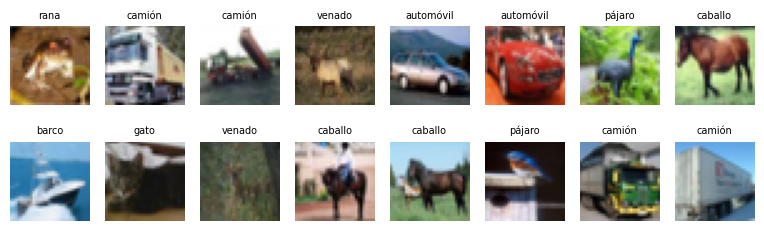

In [22]:
def to_display(images):
    # Convierte imágenes en [-1, 1] o [0, 1] a [0, 1] para mostrarlas
    images = np.asarray(images, dtype=np.float32)
    if images.min() < 0:
        images = (images + 1) / 2
    return np.clip(images, 0, 1)

def plot_multiple_images(images, n_cols=None, titles=None, size=1.2):
    images = to_display(images)
    n_cols = n_cols or len(images)
    n_rows = (len(images) - 1) // n_cols + 1
    plt.figure(figsize=(n_cols * size, n_rows * size * (1.15 if titles is not None else 1)))
    for index, image in enumerate(images):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(image)
        if titles is not None:
            plt.title(titles[index], fontsize=7)
        plt.axis("off")

print("Imágenes reales de CIFAR-10:")
plot_multiple_images(X_train[:16], 8, titles=[CLASS_NAMES[y] for y in y_train[:16]])
plt.show()

## 2. Proceso de difusión directo

Misma programación coseno del *Improved DDPM*, pero con **T = 1000**. Para imágenes de 32×32 la diferencia de calidad frente a 4000 pasos es mínima, y la generación es cuatro veces más rápida, lo que nos permite producir las miles de imágenes que exige el FID.

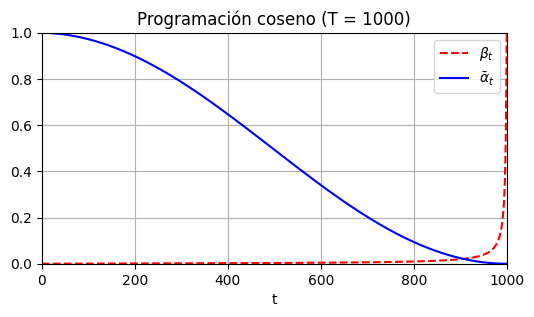

In [23]:
def variance_schedule(T, s=0.008, max_beta=0.999):
    t = np.arange(T + 1)
    f = np.cos((t / T + s) / (1 + s) * np.pi / 2) ** 2
    alpha = np.clip(f[1:] / f[:-1], 1 - max_beta, 1)
    alpha = np.append(1, alpha).astype(np.float32)
    beta = 1 - alpha
    alpha_cumprod = np.cumprod(alpha)
    return alpha, alpha_cumprod, beta

np.random.seed(42)
T = 1000
alpha, alpha_cumprod, beta = variance_schedule(T)

plt.figure(figsize=(6, 3))
plt.plot(beta, "r--", label=r"$\beta_t$"); plt.plot(alpha_cumprod, "b", label=r"$\bar{\alpha}_t$")
plt.axis([0, T, 0, 1]); plt.grid(True); plt.xlabel("t"); plt.legend()
plt.title(f"Programación coseno (T = {T})"); plt.show()

In [24]:
def prepare_batch(X):
    # CAMBIO: CIFAR ya tiene 3 canales (no se añade eje) y aplicamos volteo horizontal aleatorio
    X = tf.cast(X, tf.float32)
    X = tf.image.random_flip_left_right(X)
    X = X * 2 - 1                                     # [0,1] -> [-1,1]
    X_shape = tf.shape(X)
    t = tf.random.uniform([X_shape[0]], minval=1, maxval=T + 1, dtype=tf.int32)
    alpha_cm = tf.gather(alpha_cumprod, t)
    alpha_cm = tf.reshape(alpha_cm, [X_shape[0], 1, 1, 1])
    noise = tf.random.normal(X_shape)
    return {"X_noisy": alpha_cm ** 0.5 * X + (1 - alpha_cm) ** 0.5 * noise, "time": t}, noise

def prepare_dataset(X, batch_size=64, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(X)
    if shuffle:
        ds = ds.shuffle(10_000)
    return ds.batch(batch_size).map(prepare_batch, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

tf.random.set_seed(43)
BATCH_SIZE = 64
train_set = prepare_dataset(X_train, batch_size=BATCH_SIZE, shuffle=True)
valid_set = prepare_dataset(X_valid, batch_size=BATCH_SIZE)

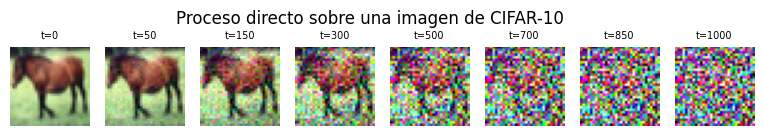

Reconstruidas / ruidosas:


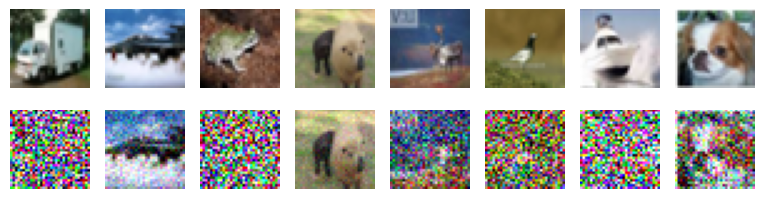

In [25]:
# Comprobación visual del proceso directo sobre una imagen a color
x0 = X_train[7] * 2 - 1
steps_to_show = [int(T * f) for f in (0, 0.05, 0.15, 0.3, 0.5, 0.7, 0.85, 1.0)]
eps = np.random.randn(*x0.shape).astype(np.float32)
noisy = [np.sqrt(alpha_cumprod[t]) * x0 + np.sqrt(1 - alpha_cumprod[t]) * eps for t in steps_to_show]
plot_multiple_images(np.array(noisy), 8, titles=[f"t={t}" for t in steps_to_show])
plt.suptitle("Proceso directo sobre una imagen de CIFAR-10", y=1.05); plt.show()

# Y comprobamos que restando el ruido recuperamos la original (sanity check del pipeline)
X_dict, Y_noise = next(iter(train_set))
ab = tf.reshape(tf.gather(alpha_cumprod, X_dict["time"]), [-1, 1, 1, 1])
X_rec = (X_dict["X_noisy"] - (1 - ab) ** 0.5 * Y_noise) / ab ** 0.5
print("Reconstruidas / ruidosas:")
plot_multiple_images(np.concatenate([X_rec[:8], X_dict["X_noisy"][:8]]), 8); plt.show()

## 3. UNet para imágenes a color

Conservamos la idea del modelo del ejemplo (bloques `SeparableConv2D` + `BatchNormalization`, conexiones residuales, saltos cruzados de la UNet y la codificación temporal sumada a cada píxel), con estos cambios:

- **Entrada 32×32×3 sin `ZeroPadding2D`** y **sin recorte final**: 32 ya se puede dividir tres veces entre 2 (32→16→8→4).
- **Salida `Conv2D(3)`**: la red predice el ruido en los tres canales RGB.
- **Más filtros** (64 → 128 → 256 → 256): el color y la textura necesitan más capacidad que los dígitos.
- La codificación sinusoidal del tiempo pasa primero por un **pequeño MLP** (como en la implementación oficial de DDPM), lo que le da a la red una representación más rica de “qué tanto ruido hay”.

In [26]:
embed_size = 128

class TimeEncoding(tf.keras.layers.Layer):
    def __init__(self, T, embed_size, dtype=tf.float32, **kwargs):
        super().__init__(dtype=dtype, **kwargs)
        assert embed_size % 2 == 0
        p, i = np.meshgrid(np.arange(T + 1), 2 * np.arange(embed_size // 2))
        t_emb = np.empty((T + 1, embed_size))
        t_emb[:, ::2] = np.sin(p / 10_000 ** (i / embed_size)).T
        t_emb[:, 1::2] = np.cos(p / 10_000 ** (i / embed_size)).T
        self.time_encodings = tf.constant(t_emb.astype(self.dtype))

    def call(self, inputs):
        return tf.gather(self.time_encodings, inputs)


def build_diffusion_model_color(img_shape=(32, 32, 3), base_dim=64,
                                down_dims=(128, 256, 256), up_dims=(256, 128, 64)):
    X_noisy = tf.keras.layers.Input(shape=img_shape, name="X_noisy")
    time_input = tf.keras.layers.Input(shape=[], dtype=tf.int32, name="time")
    time_enc = TimeEncoding(T, embed_size)(time_input)
    time_enc = tf.keras.layers.Dense(embed_size * 2, activation="swish")(time_enc)  # MLP del tiempo
    time_enc = tf.keras.layers.Dense(embed_size * 2, activation="swish")(time_enc)

    # CAMBIO: sin ZeroPadding; convolución 'same' directamente sobre 32x32x3
    Z = tf.keras.layers.Conv2D(base_dim, 3, padding="same")(X_noisy)
    Z = tf.keras.layers.BatchNormalization()(Z)
    Z = tf.keras.layers.Activation("relu")(Z)
    time = tf.keras.layers.Dense(base_dim)(time_enc)
    Z = time[:, tf.newaxis, tf.newaxis, :] + Z

    skip = Z
    cross_skips = []

    # ----- Codificador: 32 -> 16 -> 8 -> 4 -----
    for dim in down_dims:
        Z = tf.keras.layers.Activation("relu")(Z)
        Z = tf.keras.layers.SeparableConv2D(dim, 3, padding="same")(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)
        Z = tf.keras.layers.Activation("relu")(Z)
        Z = tf.keras.layers.SeparableConv2D(dim, 3, padding="same")(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)

        cross_skips.append(Z)
        Z = tf.keras.layers.MaxPooling2D(3, strides=2, padding="same")(Z)
        skip_link = tf.keras.layers.Conv2D(dim, 1, strides=2, padding="same")(skip)
        Z = tf.keras.layers.add([Z, skip_link])

        time = tf.keras.layers.Dense(dim)(time_enc)
        Z = time[:, tf.newaxis, tf.newaxis, :] + Z
        skip = Z

    # ----- Decodificador: 4 -> 8 -> 16 -> 32 -----
    for dim in up_dims:
        Z = tf.keras.layers.Activation("relu")(Z)
        Z = tf.keras.layers.Conv2DTranspose(dim, 3, padding="same")(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)
        Z = tf.keras.layers.Activation("relu")(Z)
        Z = tf.keras.layers.Conv2DTranspose(dim, 3, padding="same")(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)

        Z = tf.keras.layers.UpSampling2D(2)(Z)
        skip_link = tf.keras.layers.UpSampling2D(2)(skip)
        skip_link = tf.keras.layers.Conv2D(dim, 1, padding="same")(skip_link)
        Z = tf.keras.layers.add([Z, skip_link])

        time = tf.keras.layers.Dense(dim)(time_enc)
        Z = time[:, tf.newaxis, tf.newaxis, :] + Z
        Z = tf.keras.layers.concatenate([Z, cross_skips.pop()], axis=-1)
        skip = Z

    # CAMBIO: 3 canales de salida y sin recorte
    outputs = tf.keras.layers.Conv2D(img_shape[-1], 3, padding="same")(Z)
    return tf.keras.Model(inputs=[X_noisy, time_input], outputs=[outputs])

tf.random.set_seed(42)
model = build_diffusion_model_color(IMG_SHAPE)
print(f"Parámetros del modelo: {model.count_params():,}")

Parámetros del modelo: 3,114,947


## 4. Entrenamiento con promedio móvil exponencial (EMA)

En los modelos de difusión es práctica estándar (DDPM, Improved DDPM, Stable Diffusion) **generar con una copia de los pesos promediada en el tiempo**:

$$\theta_{EMA} \leftarrow 0.999\,\theta_{EMA} + 0.001\,\theta$$

Los pesos “crudos” oscilan bastante de un lote a otro porque cada lote ve pasos $t$ distintos; la versión EMA es más estable y produce imágenes notablemente más limpias. La implementamos con un *callback* que actualiza un segundo modelo después de cada lote, y lo guardamos al final de cada época (así no se pierde el trabajo si Colab se desconecta).

In [27]:
EPOCHS = 40
EMA_DECAY = 0.999

ema_model = build_diffusion_model_color(IMG_SHAPE)
ema_model.set_weights(model.get_weights())

class EMACallback(tf.keras.callbacks.Callback):
    def __init__(self, ema_model, decay=0.999, path="cifar_diffusion_ema.weights.h5"):
        super().__init__()
        self.ema_model, self.decay, self.path = ema_model, decay, path

    @tf.function
    def _update(self):
        for w_ema, w in zip(self.ema_model.weights, self.model.weights):
            w_ema.assign(self.decay * w_ema + (1.0 - self.decay) * w)

    def on_train_batch_end(self, batch, logs=None):
        self._update()

    def on_epoch_end(self, epoch, logs=None):
        self.ema_model.save_weights(self.path)

model.compile(loss=tf.keras.losses.Huber(),
              optimizer=tf.keras.optimizers.Nadam(learning_rate=5e-4, clipnorm=1.0))

callbacks = [
    EMACallback(ema_model, EMA_DECAY),
    tf.keras.callbacks.ModelCheckpoint("cifar_diffusion_best.weights.h5", save_best_only=True, save_weights_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4, verbose=1),
]

t0 = time.time()
history = model.fit(train_set, validation_data=valid_set, epochs=EPOCHS, callbacks=callbacks)
print(f"Tiempo de entrenamiento: {(time.time() - t0) / 60:.1f} min")

Epoch 1/40
  6/704 [..............................] - ETA: 1:09 - loss: 1.4232

704/704 [==============================] - 87s 88ms/step - loss: 0.1213 - val_loss: 0.0636 - lr: 5.0000e-04
Epoch 2/40
704/704 [==============================] - 62s 87ms/step - loss: 0.0569 - val_loss: 0.0513 - lr: 5.0000e-04
Epoch 3/40
704/704 [==============================] - 61s 87ms/step - loss: 0.0482 - val_loss: 0.0476 - lr: 5.0000e-04
Epoch 4/40
704/704 [==============================] - 62s 89ms/step - loss: 0.0444 - val_loss: 0.0462 - lr: 5.0000e-04
Epoch 5/40
704/704 [==============================] - 63s 89ms/step - loss: 0.0423 - val_loss: 0.0451 - lr: 5.0000e-04
Epoch 6/40
704/704 [==============================] - 61s 87ms/step - loss: 0.0408 - val_loss: 0.0408 - lr: 5.0000e-04
Epoch 7/40
704/704 [==============================] - 60s 86ms/step - loss: 0.0395 - val_loss: 0.0425 - lr: 5.0000e-04
Epoch 8/40
704/704 [==============================] - 61s 87ms/step - loss: 0.0384 - val_loss: 0.0392 - lr: 5.0000e-04
Epoch 9/40
704/704 [==============================] - 63s 8

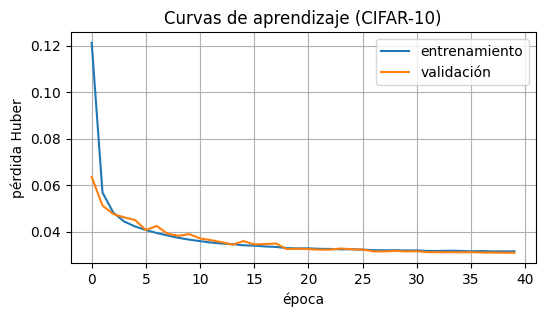

val_loss pesos crudos: 0.03101932629942894
val_loss pesos EMA   : 0.03092251531779766


In [28]:
plt.figure(figsize=(6, 3))
plt.plot(history.history["loss"], label="entrenamiento")
plt.plot(history.history["val_loss"], label="validación")
plt.xlabel("época"); plt.ylabel("pérdida Huber"); plt.grid(True); plt.legend()
plt.title("Curvas de aprendizaje (CIFAR-10)"); plt.show()

# Pérdida de validación de los pesos EMA vs. los pesos crudos
ema_model.compile(loss=tf.keras.losses.Huber())
print("val_loss pesos crudos:", model.evaluate(valid_set, verbose=0))
print("val_loss pesos EMA   :", ema_model.evaluate(valid_set, verbose=0))

## 5. Generación: DDPM y DDIM

**DDPM** (el del ejemplo) recorre los $T$ pasos uno a uno con la ecuación del Algoritmo 2. Lo compilamos con `tf.function` para que sea rápido.

**DDIM** (*Denoising Diffusion Implicit Models*, Song et al. 2021) usa **el mismo modelo entrenado**, sin reentrenar, pero salta pasos: en cada paso estima la imagen limpia $\hat x_0$ y la vuelve a “ensuciar” hasta un $t$ anterior de forma determinista:

$$\hat x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\,\varepsilon_\theta}{\sqrt{\bar\alpha_t}},\qquad x_{t'}=\sqrt{\bar\alpha_{t'}}\,\hat x_0+\sqrt{1-\bar\alpha_{t'}}\,\varepsilon_\theta$$

Con 100 pasos en lugar de 1000 es 10× más rápido. Es la misma idea que usan Stable Diffusion y los modelos modernos (que generan en 20–50 pasos).

[ddpm] 64/64 imágenes 
64 imágenes DDPM (1000 pasos) en 18.8 s


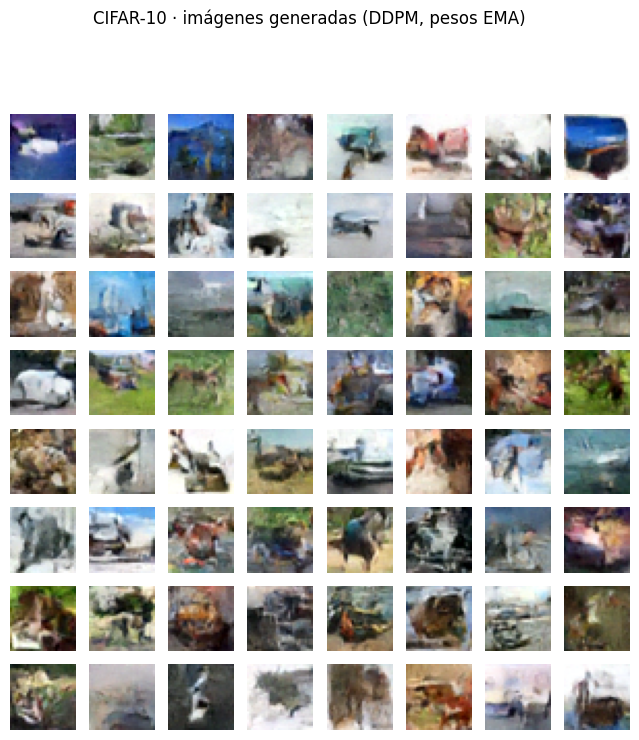

In [29]:
alpha_tf, beta_tf, ab_tf = tf.constant(alpha), tf.constant(beta), tf.constant(alpha_cumprod)

@tf.function
def ddpm_step(net, X, t):
    batch = tf.shape(X)[0]
    eps = net({"X_noisy": X, "time": tf.fill([batch], t)}, training=False)
    a_t, b_t, ab_t = tf.gather(alpha_tf, t), tf.gather(beta_tf, t), tf.gather(ab_tf, t)
    mean = (X - b_t / tf.sqrt(1 - ab_t) * eps) / tf.sqrt(a_t)
    z = tf.random.normal(tf.shape(X)) * tf.cast(t > 1, tf.float32)
    return mean + tf.sqrt(b_t) * z

@tf.function
def ddim_step(net, X, t, t_prev):
    batch = tf.shape(X)[0]
    eps = net({"X_noisy": X, "time": tf.fill([batch], t)}, training=False)
    ab_t, ab_prev = tf.gather(ab_tf, t), tf.gather(ab_tf, t_prev)
    x0 = tf.clip_by_value((X - tf.sqrt(1 - ab_t) * eps) / tf.sqrt(ab_t), -1, 1)  # estimación de la imagen limpia
    eps = (X - tf.sqrt(ab_t) * x0) / tf.sqrt(1 - ab_t)                           # ruido coherente con x0 recortado
    return tf.sqrt(ab_prev) * x0 + tf.sqrt(1 - ab_prev) * eps, x0

def generate(net, n_images, method="ddpm", ddim_steps=100, batch_size=250,
             snapshot_steps=None, verbose=True):
    outputs, snaps = [], {}
    if method == "ddpm":
        schedule = list(range(T - 1, 0, -1))   # desde T-1: en t = T, α_T ≈ 0.001 y el paso amplifica ~32×
    else:
        schedule = list(np.linspace(T - 1, 1, ddim_steps).round().astype(int))
    for start in range(0, n_images, batch_size):
        bs = min(batch_size, n_images - start)
        X = tf.random.normal([bs, *IMG_SHAPE])
        for k, t in enumerate(schedule):
            t_tf = tf.constant(int(t), tf.int32)
            if method == "ddpm":
                X = ddpm_step(net, X, t_tf); t_now = t - 1
            else:
                t_prev = int(schedule[k + 1]) if k + 1 < len(schedule) else 0
                X, _ = ddim_step(net, X, t_tf, tf.constant(t_prev, tf.int32)); t_now = t_prev
            if snapshot_steps is not None and start == 0 and t_now in snapshot_steps:
                snaps[t_now] = X.numpy()
        if verbose:
            print(f"\r[{method}] {start + bs}/{n_images} imágenes", end=" ")
        outputs.append(tf.clip_by_value(X, -1, 1).numpy())
    if verbose:
        print()
    X_gen = np.concatenate(outputs)
    return (X_gen, snaps) if snapshot_steps is not None else X_gen

# Usamos los pesos EMA para generar
tf.random.set_seed(42)
snap_steps = [T - 2] + [int(T * f) for f in (0.8, 0.6, 0.45, 0.3, 0.2, 0.1, 0.05, 0.02)] + [0]
t0 = time.time()
X_demo, snaps = generate(ema_model, 64, method="ddpm", batch_size=64, snapshot_steps=snap_steps)
print(f"64 imágenes DDPM ({T} pasos) en {time.time() - t0:.1f} s")
plot_multiple_images(X_demo, 8, size=1.0)
plt.suptitle("CIFAR-10 · imágenes generadas (DDPM, pesos EMA)", y=1.01); plt.show()

### Visualización del proceso inverso
Cada fila es una muestra distinta. Primero aparecen las manchas de color y la composición general (fondo vs. objeto); los bordes y detalles finos llegan al final.

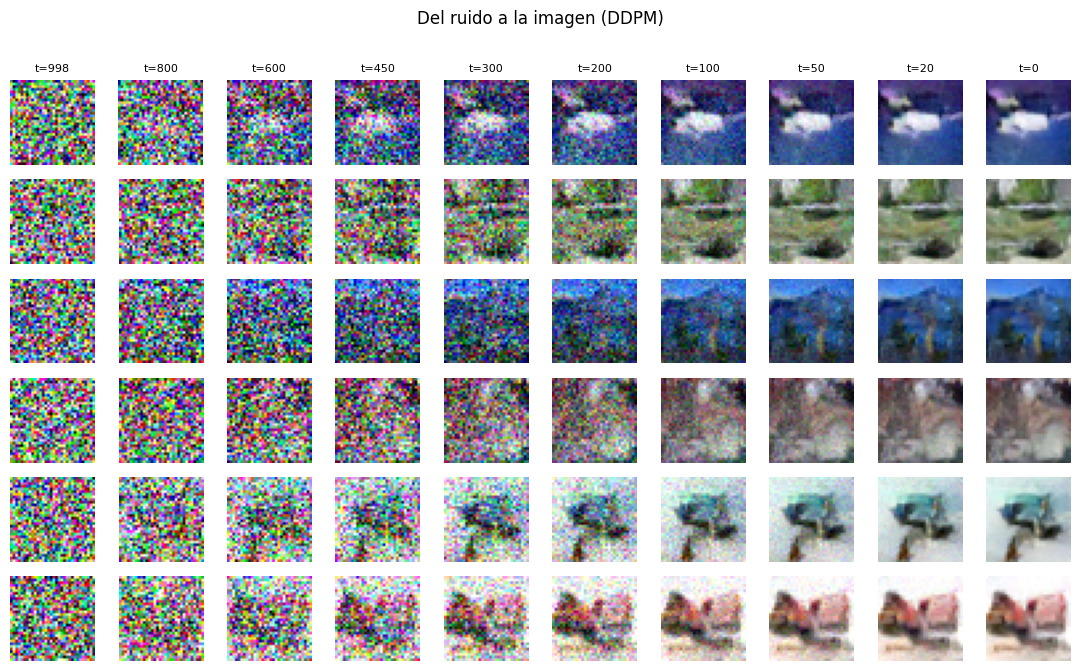

In [30]:
order = sorted(snaps.keys(), reverse=True)
n_show = 6
fig, axes = plt.subplots(n_show, len(order), figsize=(len(order) * 1.1, n_show * 1.1))
for r in range(n_show):
    for c, t in enumerate(order):
        axes[r, c].imshow(to_display(np.clip(snaps[t][r], -1, 1)))
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(f"t={t}", fontsize=8)
plt.suptitle("Del ruido a la imagen (DDPM)", y=1.01); plt.tight_layout(); plt.show()

[ddim] 64/64 imágenes 
64 imágenes DDIM (100 pasos) en 2.6 s


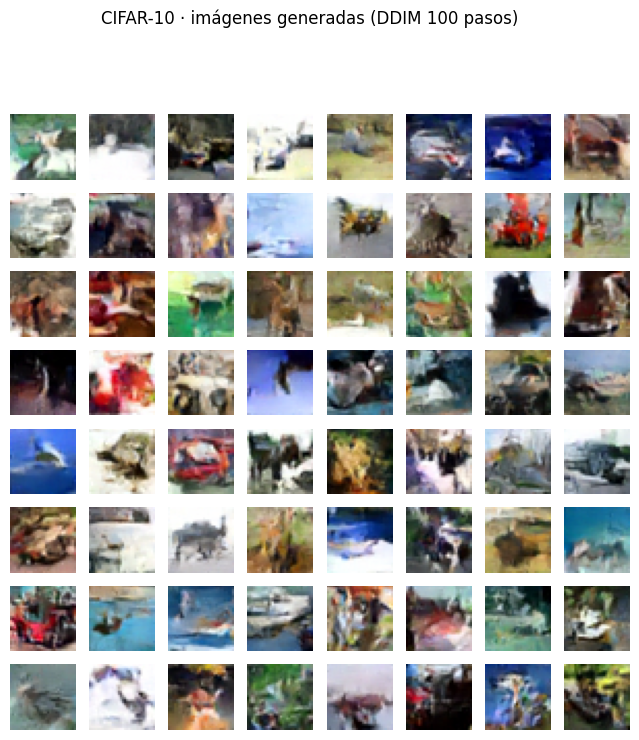

In [31]:
# DDIM: mismo modelo, 100 pasos en lugar de 1000
tf.random.set_seed(42)
t0 = time.time()
X_demo_ddim = generate(ema_model, 64, method="ddim", ddim_steps=100, batch_size=64)
print(f"64 imágenes DDIM (100 pasos) en {time.time() - t0:.1f} s")
plot_multiple_images(X_demo_ddim, 8, size=1.0)
plt.suptitle("CIFAR-10 · imágenes generadas (DDIM 100 pasos)", y=1.01); plt.show()

## 6. Evaluación cuantitativa

Para imágenes naturales a color usamos las métricas estándar de la literatura, todas basadas en **InceptionV3 preentrenada en ImageNet** (las imágenes se reescalan de 32×32 a 299×299):

- **FID** (Heusel et al., 2017): distancia de Fréchet entre las gaussianas que mejor ajustan las características de 2048 dimensiones (capa `avg_pool`) de imágenes reales y generadas. Mide calidad y diversidad a la vez. **Más bajo es mejor.**
- **KID** (Bińkowski et al., 2018): MMD² con kernel polinomial sobre las mismas características. Insesgado, por eso es más confiable que el FID cuando tenemos pocas miles de muestras. **Más bajo es mejor.**
- **Inception Score** (Salimans et al., 2016): $\exp(\mathbb E_x KL(p(y|x)\,\|\,p(y)))$ con las 1000 clases de ImageNet. Premia imágenes reconocibles y variadas. **Más alto es mejor.**

Como el FID depende del número de muestras, siempre reportamos también la **línea base real vs real** con el mismo $N$: ese es el “piso” alcanzable.

> Nota: los valores de la implementación de Keras pueden diferir un poco de la implementación oficial (`pytorch-fid`/TTUR) por detalles del redimensionado y los pesos de Inception, pero son perfectamente válidos para comparar modelos entre sí.

In [32]:
inception = tf.keras.applications.InceptionV3(include_top=True, weights="imagenet")
inception_both = tf.keras.Model(inception.input,
                                [inception.get_layer("avg_pool").output, inception.output])

@tf.function
def _inception_forward(x):
    x = tf.image.resize(x, (299, 299), method="bilinear")   # InceptionV3 espera [-1,1] y 299x299
    return inception_both(x, training=False)

def inception_feats_probs(X, batch_size=100):
    feats, probs = [], []
    for i in range(0, len(X), batch_size):
        f, p = _inception_forward(tf.constant(X[i:i + batch_size], tf.float32))
        feats.append(f.numpy()); probs.append(p.numpy())
    return np.concatenate(feats).astype(np.float64), np.concatenate(probs).astype(np.float64)

def fid(f1, f2):
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    covmean = linalg.sqrtm(s1.dot(s2))
    covmean = covmean[0] if isinstance(covmean, tuple) else covmean
    if not np.isfinite(covmean).all():
        off = np.eye(s1.shape[0]) * 1e-6
        covmean = linalg.sqrtm((s1 + off).dot(s2 + off))
        covmean = covmean[0] if isinstance(covmean, tuple) else covmean
    covmean = covmean.real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean))

def kid(f1, f2, n_subsets=50, subset_size=1000, seed=0):
    rng = np.random.default_rng(seed)
    d = f1.shape[1]
    m = min(subset_size, len(f1), len(f2))
    vals = []
    for _ in range(n_subsets):
        x = f1[rng.choice(len(f1), m, replace=False)]
        y = f2[rng.choice(len(f2), m, replace=False)]
        kxx, kyy, kxy = (x @ x.T / d + 1) ** 3, (y @ y.T / d + 1) ** 3, (x @ y.T / d + 1) ** 3
        vals.append((kxx.sum() - np.trace(kxx)) / (m * (m - 1))
                    + (kyy.sum() - np.trace(kyy)) / (m * (m - 1)) - 2 * kxy.mean())
    return float(np.mean(vals)), float(np.std(vals))

def inception_score(probs, splits=10):
    scores = []
    for part in np.array_split(probs, splits):
        py = part.mean(0, keepdims=True)
        scores.append(np.exp((part * (np.log(part + 1e-12) - np.log(py + 1e-12))).sum(1).mean()))
    return float(np.mean(scores)), float(np.std(scores))

### 6.1 Generar el conjunto de evaluación
2.000 imágenes con DDPM (1000 pasos) y 2.000 con DDIM (100 pasos). En una T4 la parte DDPM tarda unos minutos; si tienes poco tiempo de GPU baja `N_EVAL` a 1000.

In [33]:
N_EVAL = 2000

tf.random.set_seed(2024)
t0 = time.time(); X_gen_ddpm = generate(ema_model, N_EVAL, method="ddpm"); t_ddpm = time.time() - t0
t0 = time.time(); X_gen_ddim = generate(ema_model, N_EVAL, method="ddim", ddim_steps=100); t_ddim = time.time() - t0
print(f"DDPM: {t_ddpm / 60:.1f} min | DDIM: {t_ddim / 60:.1f} min")

rng = np.random.default_rng(0)
X_real_test = X_test[rng.choice(len(X_test), N_EVAL, replace=False)] * 2 - 1
X_real_train = X_train[rng.choice(len(X_train), N_EVAL, replace=False)] * 2 - 1
X_noise = np.clip(np.random.randn(N_EVAL, *IMG_SHAPE), -1, 1).astype(np.float32)

t0 = time.time()
f_test, p_test = inception_feats_probs(X_real_test)
f_train, p_train = inception_feats_probs(X_real_train)
f_ddpm, p_ddpm = inception_feats_probs(X_gen_ddpm)
f_ddim, p_ddim = inception_feats_probs(X_gen_ddim)
f_noise, p_noise = inception_feats_probs(X_noise)
print(f"Características de Inception calculadas en {(time.time() - t0) / 60:.1f} min")

[ddpm] 2000/2000 imágenes 
[ddim] 2000/2000 imágenes 
DDPM: 9.1 min | DDIM: 0.9 min
Características de Inception calculadas en 0.6 min


In [34]:
rows = []
for name, f, p, secs in [("Real (train) — línea base", f_train, p_train, None),
                         ("Difusión DDPM (1000 pasos)", f_ddpm, p_ddpm, t_ddpm),
                         ("Difusión DDIM (100 pasos)", f_ddim, p_ddim, t_ddim),
                         ("Ruido gaussiano — peor caso", f_noise, p_noise, None)]:
    k, k_std = kid(f, f_test)
    is_m, is_s = inception_score(p)
    rows.append({"Conjunto": name, "FID ↓": fid(f, f_test), "KID×1000 ↓": 1000 * k,
                 "KID std×1000": 1000 * k_std, "IS ↑": is_m, "IS std": is_s,
                 "seg / imagen": (secs / N_EVAL) if secs else np.nan})

results = pd.DataFrame(rows).set_index("Conjunto")
pd.options.display.float_format = "{:.3f}".format
print(f"Distancias calculadas contra {N_EVAL} imágenes reales de PRUEBA")
display(results)

Distancias calculadas contra 2000 imágenes reales de PRUEBA


,FID ↓,KID×1000 ↓,KID std×1000,IS ↑,IS std,seg / imagen
Conjunto,,,,,,
Real (train) — línea base,26.168,0.012,0.116,9.703,0.567,NaN
Difusión DDPM (1000 pasos),78.964,46.273,1.201,4.333,0.235,0.274
Difusión DDIM (100 pasos),75.575,44.785,1.129,4.336,0.243,0.028
Ruido gaussiano — peor caso,610.509,896.562,4.152,1.272,0.009,NaN


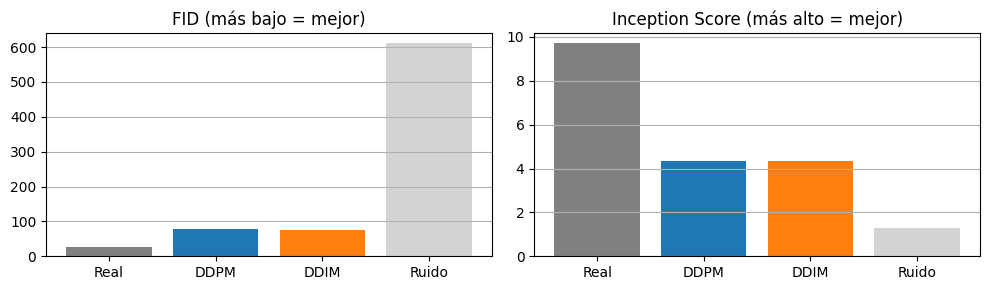

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
names = ["Real", "DDPM", "DDIM", "Ruido"]
ax[0].bar(names, results["FID ↓"], color=["gray", "tab:blue", "tab:orange", "lightgray"])
ax[0].set_title("FID (más bajo = mejor)"); ax[0].grid(axis="y")
ax[1].bar(names, results["IS ↑"], color=["gray", "tab:blue", "tab:orange", "lightgray"])
ax[1].set_title("Inception Score (más alto = mejor)"); ax[1].grid(axis="y")
plt.tight_layout(); plt.show()

### 6.2 ¿Memoriza el modelo? Vecinos más cercanos
Buscamos, para algunas imágenes generadas, la imagen de entrenamiento más cercana en el espacio de características de Inception. Si fueran copias casi exactas habría memorización.

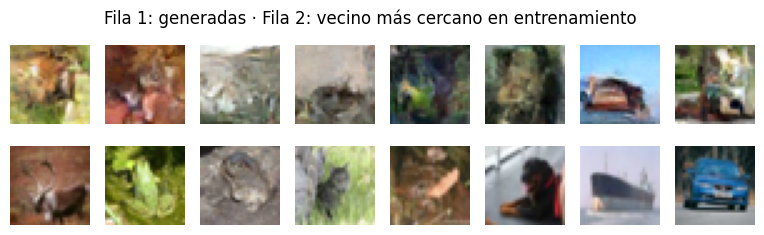

In [36]:
N_BANK = 5000
bank_idx = np.random.default_rng(1).choice(len(X_train), N_BANK, replace=False)
f_bank, _ = inception_feats_probs(X_train[bank_idx] * 2 - 1)

query = np.arange(8)
d = ((f_ddpm[query][:, None, :] - f_bank[None]) ** 2).sum(-1)
nn = bank_idx[d.argmin(1)]
plot_multiple_images(np.concatenate([X_gen_ddpm[query], X_train[nn] * 2 - 1]), 8)
plt.suptitle("Fila 1: generadas · Fila 2: vecino más cercano en entrenamiento", y=1.02); plt.show()

### 6.3 Cómo interpretar los resultados

- **Referencias de la literatura:** el DDPM original (Ho et al., 2020) logra FID ≈ 3.2 en CIFAR-10, pero con 35.7 M de parámetros, 800.000 pasos de entrenamiento y 50.000 muestras. Nuestro modelo es mucho más pequeño y se entrena ~28.000 pasos, así que es esperable un FID bastante más alto. Lo importante es dónde queda **entre la línea base real y el ruido**.
- **El FID con 2.000 muestras está sesgado hacia arriba**: por eso incluso “real vs real” da un número mayor que cero. El KID no tiene ese sesgo, así que úsalo como confirmación.
- **DDPM vs DDIM:** normalmente DDIM con 100 pasos queda cerca de DDPM con 1000, a una décima parte del tiempo. Esto es justamente lo que permitió que los modelos de difusión se volvieran prácticos.
- **Cualitativamente**, el modelo suele capturar muy bien la distribución de colores y la composición (cielo azul arriba, pasto verde abajo, objeto centrado), pero los objetos salen poco definidos: a 32×32 y con esta capacidad, la red aprende “la idea” de un caballo o un barco más que su forma exacta. Comparado con MNIST, el salto de dificultad se nota claramente en las métricas.

**Posibles mejoras** (para la discusión o la sustentación): más épocas, más filtros, *attention* a resolución 16×16 y `GroupNormalization` en vez de `BatchNormalization` (como el UNet del DDPM oficial), condicionar por clase con *classifier-free guidance*, y evaluar con 10.000–50.000 muestras.

> 📝 Después de correr el notebook, reemplaza este párrafo con tus números reales y tu análisis.

In [37]:
ema_model.save_weights("cifar_diffusion_ema_final.weights.h5")
np.save("cifar_generated_ddpm.npy", X_gen_ddpm[:256])
results.to_csv("cifar_metricas.csv")
print("Guardado: cifar_diffusion_ema_final.weights.h5, cifar_generated_ddpm.npy, cifar_metricas.csv")

Guardado: cifar_diffusion_ema_final.weights.h5, cifar_generated_ddpm.npy, cifar_metricas.csv
